# Домашнее задание по машинному обучению
## Ultimate Steam Dataset 2026 — предсказание успеха игры

**Датасет:** [Ultimate Steam Dataset 2026](https://www.kaggle.com/datasets/pratyushgosain/ultimate-steam-dataset-2026)
**Файл:** `ultimate_steam_games_v1.csv` (3381 игра, 26 столбцов)

## 0. Постановка задачи

Нужно по характеристикам игры предсказать, станет ли она успешной.

- **Целевая переменная:** `success_label` — бинарный признак (1 — успешная, 0 — нет).
- **Тип задачи:** бинарная классификация.
- **Метрики:** accuracy, precision, recall, F1, матрица рассогласования.
  Основная — **F1 по классу 1**, поскольку классы несбалансированы (~20% успешных).

**Про утечку данных (leakage).**
Часть столбцов — это *следствие* успеха, а не причина:
`positive`, `negative`, `total_reviews`, `positive_ratio`, `owners`, `ccu`,
`average_forever`, `median_forever`, `hidden_gem_score`, `popularity_tier`.
Скорее всего, `success_label` построен именно по ним. Если включить их в
модель, точность будет ≈ 1.0, но модель будет бесполезной. Поэтому основную
модель строим **только по метаданным, доступным на момент релиза**:
цена, год, жанры, категории, число языков, число разработчиков/издателей,
бесплатность. В конце отдельной секцией покажем, как «утечка» поднимает
качество до 1.0.

## 1. Чтение данных и парсинг «грязных» столбцов

- `owners` — диапазон `"100,000,000 .. 200,000,000"` → берём середину.
- `price` — в центах (`5999` → `59.99 USD`).
- `release_date` — в разных локалях (`"18 трав. 2015"`, `"14 Haz 2016"`,
  `"27 أكتوبر, 2022"`) → вытаскиваем год регексом.
- `developers` / `publishers` / `genres` / `categories` / `supported_languages` —
  списки через запятую; считаем число элементов (жанры/категории кодируем позже).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import (train_test_split, GridSearchCV,
                                     StratifiedKFold, cross_val_predict)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

df = pd.read_csv("ultimate_steam_games_v1.csv")
print("Shape:", df.shape)
df.head()

Shape: (3381, 26)


,appid,name,owners,positive,negative,average_forever,median_forever,ccu,price,total_reviews,positive_ratio,hidden_gem_score,release_date,developers,publishers,genres,categories,is_free,supported_languages,language_count,genre_count,category_count,success_label,popularity_tier,hidden_gem,price_bucket
0,730,Counter-Strike: Global Offensive,"100,000,000 .. 200,000,000",7642084,1173003,0,0,1013936,0.0,8815087,0.866932,13.863961,"21 Aug, 2012",Valve,Valve,"Action, Free To Play","Multi-player, Cross-Platform Multiplayer, Stea...",True,"Czech, Danish, Dutch, English<strong>*</strong...",29,2,18,1,Platinum,0,Free
1,271590,Grand Theft Auto V Legacy,"50,000,000 .. 100,000,000",1739980,250576,0,0,67851,0.0,1990556,0.874118,12.678136,"13 Apr, 2015",Rockstar North,Rockstar Games,"Action, Adventure","Single-player, Multi-player, PvP, Online PvP, ...",False,"English<strong>*</strong>, French, Italian, Ge...",13,2,11,1,Platinum,0,Free
2,578080,PUBG: BATTLEGROUNDS,"100,000,000 .. 200,000,000",1520457,1037487,0,0,314682,0.0,2557944,0.594406,8.770289,"21 Dec, 2017",PUBG Corporation,"KRAFTON, Inc.","Action, Adventure, Massively Multiplayer, Free...","Multi-player, PvP, Online PvP, Custom Volume C...",True,"English, Korean, Simplified Chinese, French, G...",17,4,11,1,Platinum,0,Free
3,105600,Terraria,"20,000,000 .. 50,000,000",1373979,35494,0,0,24580,499.0,1409473,0.974818,13.802176,"16 May, 2011",Re-Logic,Re-Logic,"Action, Adventure, Indie, RPG","Single-player, Multi-player, PvP, Online PvP, ...",False,"English, French, Italian, German, Spanish - Sp...",9,4,14,1,Platinum,0,Budget
4,359550,Tom Clancy's Rainbow Six Siege,"20,000,000 .. 50,000,000",1172854,225730,0,0,51847,1999.0,1398584,0.838601,11.867020,"1 Dec, 2015",Ubisoft Montreal,Ubisoft,"Action, Free To Play","Single-player, Multi-player, PvP, Online PvP, ...",True,"English<strong>*</strong>, French<strong>*</st...",16,2,15,1,Platinum,0,Premium


In [2]:
def owners_mid(s):
    if pd.isna(s):
        return np.nan
    s = str(s).replace(",", "")
    if ".." in s:
        lo, hi = s.split("..")
        try:
            return (float(lo) + float(hi)) / 2
        except ValueError:
            return np.nan
    try:
        return float(s)
    except ValueError:
        return np.nan

df["owners_mid"] = df["owners"].apply(owners_mid)
df["price_usd"]  = pd.to_numeric(df["price"], errors="coerce") / 100.0
df["release_year"] = (df["release_date"].astype(str)
                      .str.extract(r"((?:19|20)\d{2})")[0]
                      .astype(float))

def count_items(s):
    if pd.isna(s):
        return 0
    items = [x.strip() for x in str(s).split(",") if x.strip()]
    return len(items)

df["developer_count"] = df["developers"].apply(count_items)
df["publisher_count"] = df["publishers"].apply(count_items)

df["is_free"] = (df["is_free"].astype(str).str.lower()
                 .map({"true": 1, "false": 0}).fillna(0).astype(int))

df[["owners", "owners_mid", "price", "price_usd",
    "release_date", "release_year",
    "developer_count", "publisher_count"]].head()

,owners,owners_mid,price,price_usd,release_date,release_year,developer_count,publisher_count
0,"100,000,000 .. 200,000,000",150000000.0,0.0,0.00,"21 Aug, 2012",2012.0,1,1
1,"50,000,000 .. 100,000,000",75000000.0,0.0,0.00,"13 Apr, 2015",2015.0,1,1
2,"100,000,000 .. 200,000,000",150000000.0,0.0,0.00,"21 Dec, 2017",2017.0,1,2
3,"20,000,000 .. 50,000,000",35000000.0,499.0,4.99,"16 May, 2011",2011.0,1,1
4,"20,000,000 .. 50,000,000",35000000.0,1999.0,19.99,"1 Dec, 2015",2015.0,1,1


In [3]:
# Проверка парсинга release_date в разных локалях
print("Примеры release_date:")
print(df["release_date"].head(10).tolist())
print("\nПримеры release_year:")
print(df["release_year"].value_counts().sort_index().head())

Примеры release_date:
['21 Aug, 2012', '13 Apr, 2015', '21 Dec, 2017', '16 May, 2011', '1 Dec, 2015', '29 Nov, 2006', '19 Aug, 2024', '8 Feb, 2018', '10 Oct, 2007', '24 Feb, 2022']

Примеры release_year:
release_year
1997.0    1
1998.0    1
1999.0    2
2000.0    2
2001.0    3
Name: count, dtype: int64


## 2. Анализ целевой переменной

Распределение классов:
success_label
0    2702
1     679
Name: count, dtype: int64

Доля класса 1: 20.08%


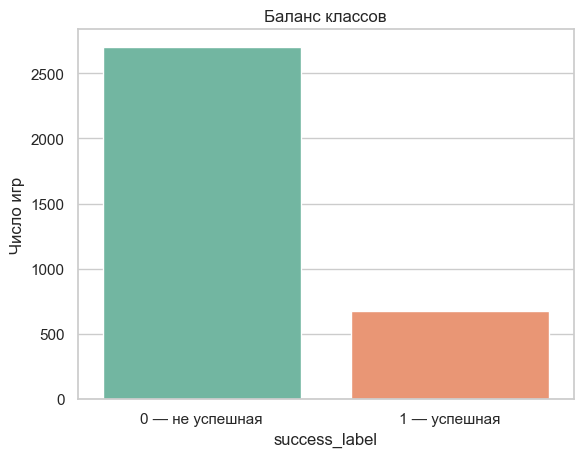

In [4]:
TARGET = "success_label"

df = df.dropna(subset=[TARGET]).copy()
df[TARGET] = df[TARGET].astype(int)

print("Распределение классов:")
print(df[TARGET].value_counts())
print("\nДоля класса 1: {:.2%}".format(df[TARGET].mean()))

sns.countplot(x=TARGET, data=df, palette="Set2")
plt.title("Баланс классов")
plt.xticks([0, 1], ["0 — не успешная", "1 — успешная"])
plt.ylabel("Число игр")
plt.show()

## 3. Разбиение на обучающую и тестовую выборки

Стратифицированное разбиение 80/20 — сохраняет долю успешных игр в обеих частях.

In [5]:
NUMERIC_FEATURES = ["price_usd", "release_year",
                    "developer_count", "publisher_count",
                    "language_count", "genre_count", "category_count"]
BINARY_FEATURES = ["is_free"]
MULTILABEL_FEATURES = ["genres", "categories"]

FEATURES = NUMERIC_FEATURES + BINARY_FEATURES + MULTILABEL_FEATURES

X = df[FEATURES].copy()
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("Доля класса 1 в train: {:.2%}".format(y_train.mean()))
print("Доля класса 1 в test : {:.2%}".format(y_test.mean()))

X_train: (2704, 10)  X_test: (677, 10)
Доля класса 1 в train: 20.08%
Доля класса 1 в test : 20.09%


## 4. Разведывательный анализ данных

Статистики, распределения, корреляционная матрица — по train, чтобы не подглядывать в тест.

In [6]:
X_train[NUMERIC_FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
price_usd,2704.0,8.08,9.46,0.0,1.99,4.99,9.99,69.99
release_year,2693.0,2018.15,4.56,1997.0,2015.00,2019.00,2022.00,2026.00
developer_count,2704.0,1.21,0.61,1.0,1.00,1.00,1.00,8.00
publisher_count,2704.0,1.17,0.49,0.0,1.00,1.00,1.00,5.00
language_count,2704.0,9.46,7.89,1.0,5.00,9.00,13.00,103.00
genre_count,2704.0,2.71,1.38,1.0,2.00,3.00,3.00,10.00
category_count,2704.0,8.92,5.00,1.0,5.00,8.00,11.00,34.00


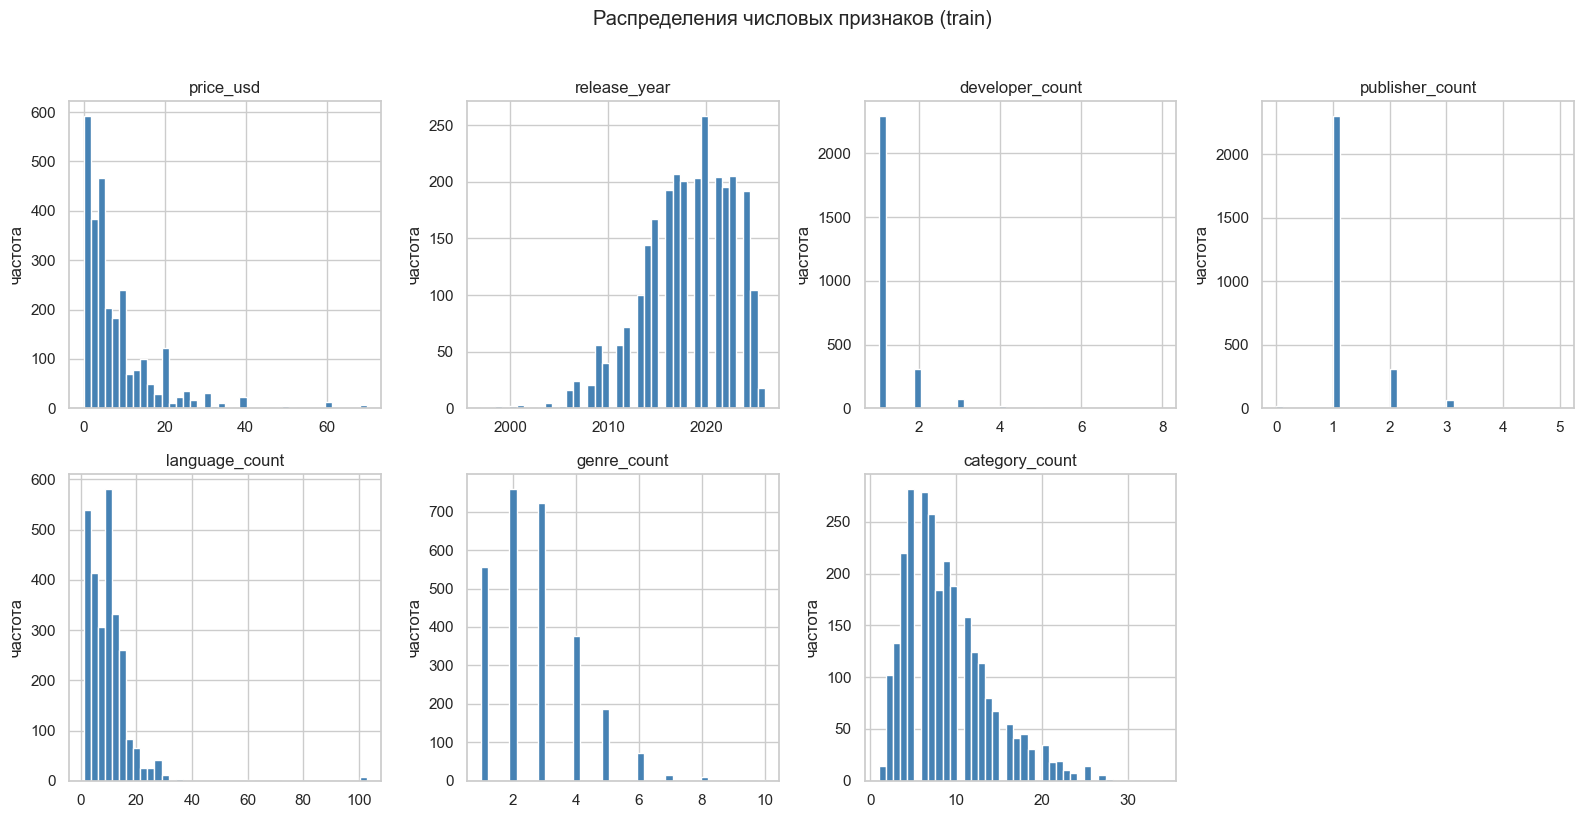

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()
for ax, col in zip(axes, NUMERIC_FEATURES):
    ax.hist(X_train[col].dropna(), bins=40, color="steelblue")
    ax.set_title(col)
    ax.set_ylabel("частота")
for ax in axes[len(NUMERIC_FEATURES):]:
    ax.axis("off")
plt.suptitle("Распределения числовых признаков (train)", y=1.02)
plt.tight_layout()
plt.show()

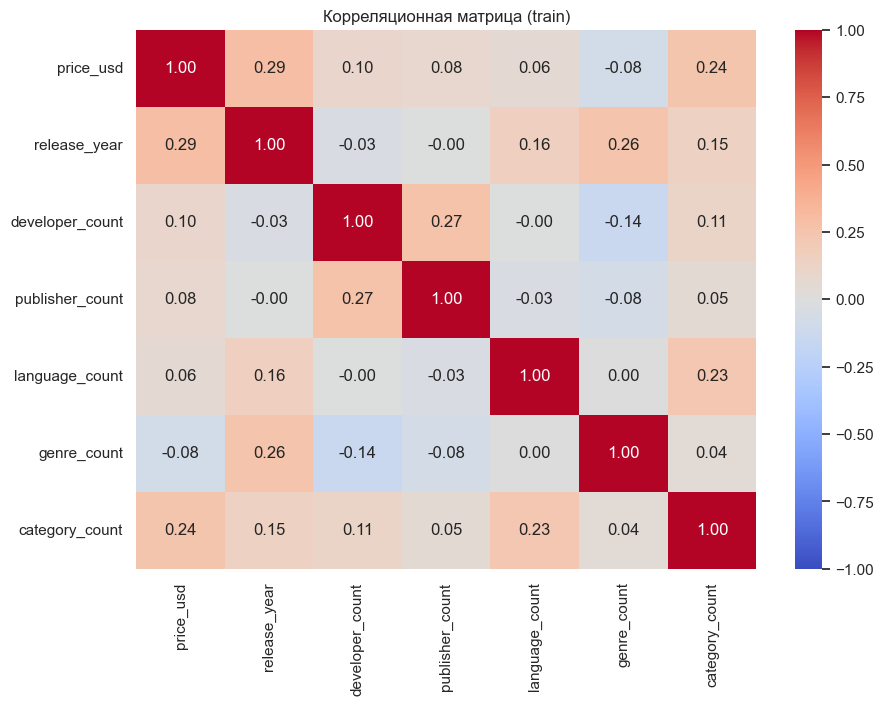

In [8]:
plt.figure(figsize=(10, 7))
sns.heatmap(X_train[NUMERIC_FEATURES].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляционная матрица (train)")
plt.show()

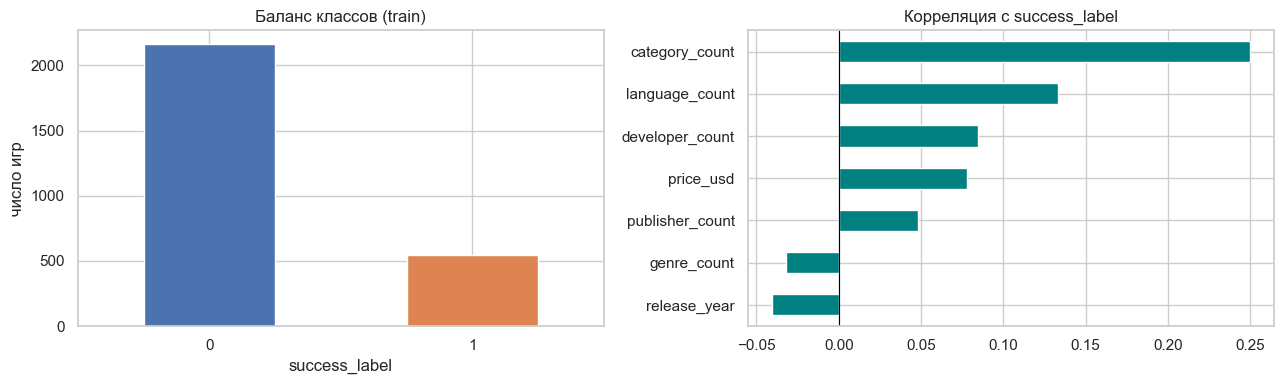

In [9]:
corr_target = X_train[NUMERIC_FEATURES].corrwith(y_train).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
y_train.value_counts().sort_index().plot(kind="bar", ax=axes[0],
                                         color=["#4c72b0", "#dd8452"])
axes[0].set_title("Баланс классов (train)")
axes[0].set_xticklabels(["0", "1"], rotation=0)
axes[0].set_ylabel("число игр")

corr_target.plot(kind="barh", ax=axes[1], color="teal")
axes[1].set_title("Корреляция с success_label")
axes[1].axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

### Интерпретация

- **Дисбаланс классов:** успешных ≈ 20%, accuracy «всегда 0» уже даёт ≈ 0.80.
  Смотрим F1/recall по классу 1.
- **Распределения цены и числа языков/жанров скошены вправо**: есть блокбастеры,
  основная масса — дешёвые инди. Повод обрезать выбросы.
- **Корреляции очень слабые** (|r| < 0.15). Метаданные почти не связаны с
  успехом: сигнал определяется качеством игры, маркетингом, студией — этого
  в «безопасных» признаках нет.

## 5. Выбросы

Обрезаем по 1–99 перцентилям, посчитанным **на train**.

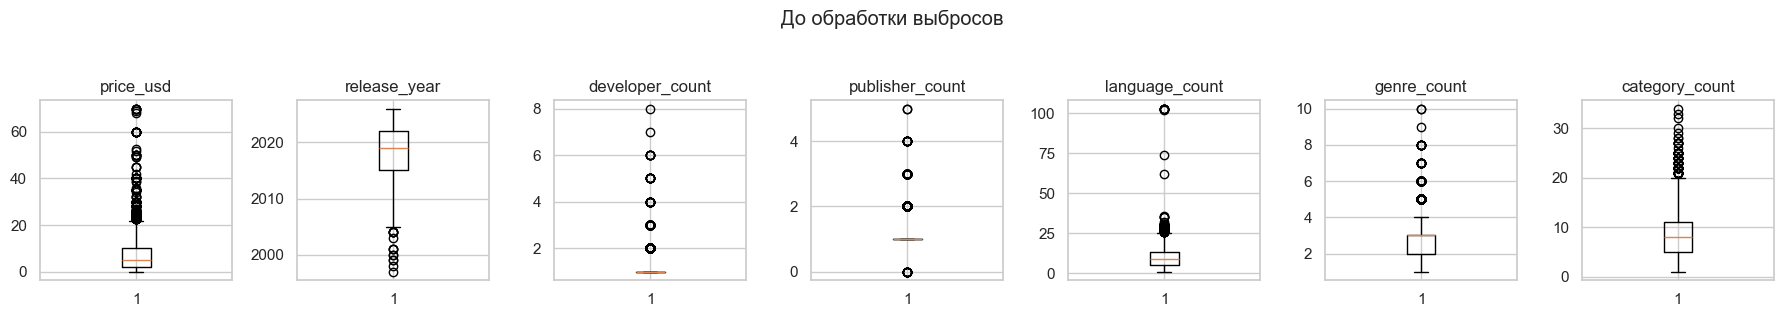

In [10]:
fig, axes = plt.subplots(1, len(NUMERIC_FEATURES), figsize=(18, 3))
for ax, col in zip(axes, NUMERIC_FEATURES):
    ax.boxplot(X_train[col].dropna())
    ax.set_title(col)
plt.suptitle("До обработки выбросов", y=1.05)
plt.tight_layout()
plt.show()

In [11]:
def cap_outliers(train, test, cols, low=0.01, high=0.99):
    tr, te = train.copy(), test.copy()
    for c in cols:
        lo, hi = train[c].quantile([low, high])
        tr[c] = tr[c].clip(lo, hi)
        te[c] = te[c].clip(lo, hi)
    return tr, te

X_train_c, X_test_c = cap_outliers(X_train, X_test, NUMERIC_FEATURES)
print("price_usd: было max = {}, стало max = {}".format(
    X_train["price_usd"].max(), X_train_c["price_usd"].max()))

price_usd: было max = 69.99, стало max = 48.8699999999992


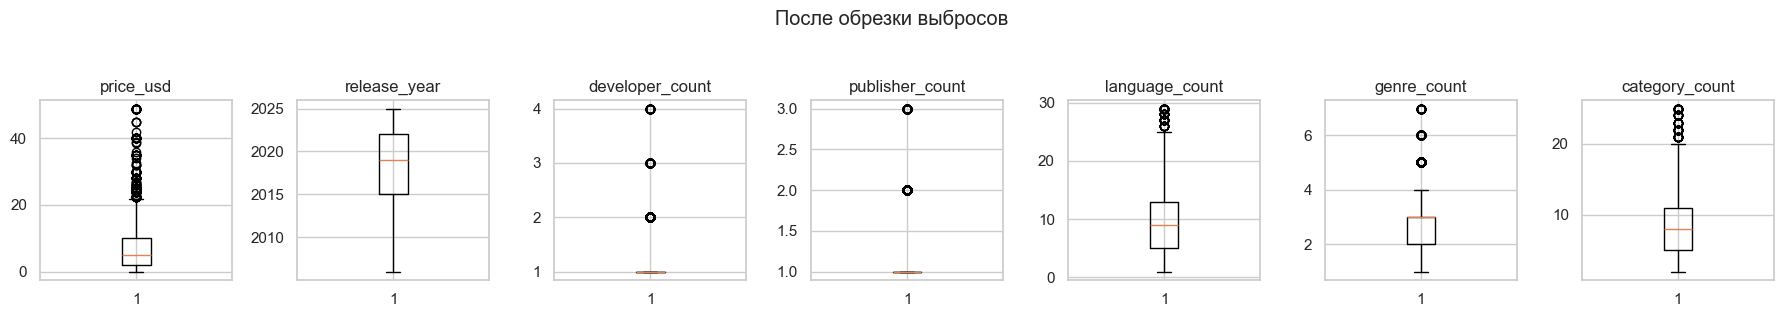

In [12]:
fig, axes = plt.subplots(1, len(NUMERIC_FEATURES), figsize=(18, 3))
for ax, col in zip(axes, NUMERIC_FEATURES):
    ax.boxplot(X_train_c[col].dropna())
    ax.set_title(col)
plt.suptitle("После обрезки выбросов", y=1.05)
plt.tight_layout()
plt.show()

## 6. Пропущенные значения

In [13]:
print("Пропуски в train:")
print(X_train_c.isna().sum()[X_train_c.isna().sum() > 0])
print("\nПропуски в test:")
print(X_test_c.isna().sum()[X_test_c.isna().sum() > 0])

if X_train_c.isna().sum().sum() == 0 and X_test_c.isna().sum().sum() == 0:
    print("\nПропусков нет — обработка не требуется.")
else:
    print("\nПропуски есть — SimpleImputer(median) встроен в Pipeline.")

Пропуски в train:
release_year    11
genres          11
categories       8
dtype: int64

Пропуски в test:
release_year    7
genres          2
categories      1
dtype: int64

Пропуски есть — SimpleImputer(median) встроен в Pipeline.


## 7. Обработка категориальных признаков

- `genres`, `categories` — **мультиметки** (`"Action, Adventure, Indie"`).
  Строим бинарные столбцы по топ-8 значениям, топ считаем на train.
- `is_free` — уже 0/1.
- `price_bucket`, `popularity_tier` — производные, не используем.

In [14]:
def top_tokens(series, n=8):
    s = series.fillna("").astype(str).str.split(",").explode().str.strip()
    s = s[s != ""]
    return s.value_counts().head(n).index.tolist()

def sanitize(s):
    return re.sub(r"[^A-Za-z0-9_]+", "_", s).strip("_")

top_genres = top_tokens(X_train_c["genres"], 8)
top_cats   = top_tokens(X_train_c["categories"], 8)
print("Топ жанры:   ", top_genres)
print("Топ категории:", top_cats)

def add_multilabel(frame, col, tokens, prefix):
    data = {}
    for t in tokens:
        key = f"{prefix}{sanitize(t)}"
        data[key] = frame[col].fillna("").astype(str).apply(
            lambda x, t=t: int(t in [i.strip() for i in x.split(",")])
        )
    return pd.DataFrame(data, index=frame.index)

def make_features(frame):
    base = frame[NUMERIC_FEATURES].copy()
    base["is_free"] = frame["is_free"].astype(int)
    ml = pd.concat([
        add_multilabel(frame, "genres",     top_genres, "genre_"),
        add_multilabel(frame, "categories", top_cats,   "cat_"),
    ], axis=1)
    return pd.concat([base, ml], axis=1)

Xtr = make_features(X_train_c)
Xte = make_features(X_test_c)
print("Xtr:", Xtr.shape, " Xte:", Xte.shape)
Xtr.head()

Топ жанры:    ['Action', 'Indie', 'Adventure', 'RPG', 'Simulation', 'Strategy', 'Casual', 'Free To Play']
Топ категории: ['Family Sharing', 'Single-player', 'Steam Achievements', 'Steam Cloud', 'DualShock Controller Support', 'Steam Trading Cards', 'Full controller support', 'Multi-player']
Xtr: (2704, 24)  Xte: (677, 24)


,price_usd,release_year,developer_count,publisher_count,language_count,genre_count,category_count,is_free,genre_Action,genre_Indie,genre_Adventure,genre_RPG,genre_Simulation,genre_Strategy,genre_Casual,genre_Free_To_Play,cat_Family_Sharing,cat_Single_player,cat_Steam_Achievements,cat_Steam_Cloud,cat_DualShock_Controller_Support,cat_Steam_Trading_Cards,cat_Full_controller_support,cat_Multi_player
1155,29.99,2022.0,1,1,13,2.0,5.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
95,9.89,2020.0,1,1,13,1.0,16.0,0,1,0,0,0,0,0,0,0,1,1,1,1,0,1,0,1
357,1.49,2020.0,2,1,10,3.0,15.0,0,0,1,0,0,0,0,1,0,1,1,1,0,0,0,0,1
3239,0.00,2016.0,3,1,6,2.0,8.0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,1,1
742,9.89,2024.0,1,1,10,2.0,11.0,0,1,1,0,0,0,0,0,0,1,0,1,0,1,0,1,1


## 8. Нормализация

**Нужна** — основной классификатор kNN считает евклидово расстояние.
`release_year` ~ 2010-е, `price_usd` ~ 0–60, `language_count` ~ 1–100 —
без масштабирования год выхода «задавит» остальные признаки.

- Числовые → `StandardScaler` (после `SimpleImputer`).
- Бинарные one-hot не масштабируем.
- Всё в `Pipeline`, чтобы `Scaler` обучался только на train.

In [15]:
bin_features = [c for c in Xtr.columns if c not in NUMERIC_FEATURES]

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler",  StandardScaler()),
    ]), NUMERIC_FEATURES),
    ("bin", "passthrough", bin_features),
])

print("Числовых:", len(NUMERIC_FEATURES), " Бинарных:", len(bin_features))

Числовых: 7  Бинарных: 17


## 9. kNN и подбор гиперпараметра `k`

`k` подбираем **кросс-валидацией на train** (5-fold stratified, метрика — F1
по классу 1, более информативна при дисбалансе, чем accuracy).

In [16]:
knn_pipe = Pipeline([
    ("prep", preprocess),
    ("clf",  KNeighborsClassifier()),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
param_grid = {"clf__n_neighbors": list(range(1, 32, 2))}

gs = GridSearchCV(knn_pipe, param_grid, cv=cv, scoring="f1", n_jobs=-1)
gs.fit(Xtr, y_train)

print("Оптимальное k:", gs.best_params_["clf__n_neighbors"])
print("CV F1 (класс 1): {:.4f}".format(gs.best_score_))

Оптимальное k: 1
CV F1 (класс 1): 0.3487


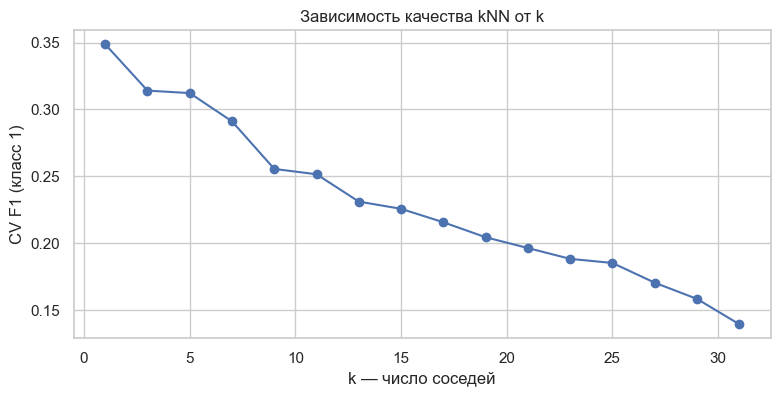

In [17]:
res = pd.DataFrame(gs.cv_results_)
plt.figure(figsize=(9, 4))
plt.plot(res["param_clf__n_neighbors"].astype(int),
         res["mean_test_score"], marker="o")
plt.xlabel("k — число соседей")
plt.ylabel("CV F1 (класс 1)")
plt.title("Зависимость качества kNN от k")
plt.grid(True)
plt.show()

## 10. Ошибки на train/test и матрица рассогласования

=== TRAIN ===
  accuracy : 0.9993
  precision: 0.9982
  recall   : 0.9982
  F1       : 0.9982

=== TEST ===
  accuracy : 0.7400
  precision: 0.3333
  recall   : 0.2941
  F1       : 0.3125



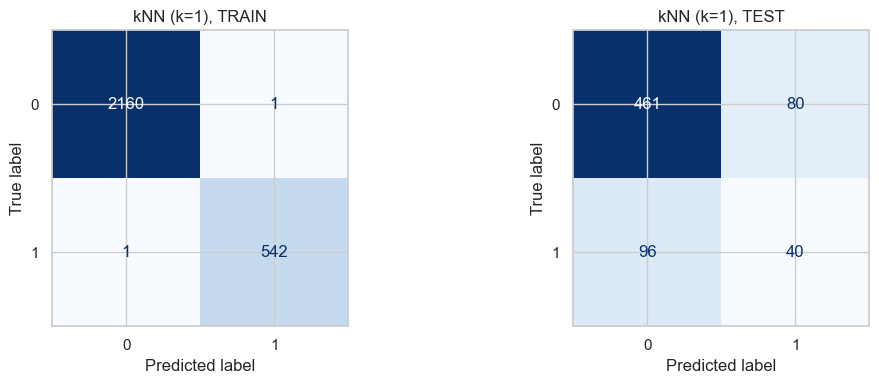

In [18]:
best_knn = gs.best_estimator_
best_k   = gs.best_params_["clf__n_neighbors"]

for name, X_, y_ in [("TRAIN", Xtr, y_train), ("TEST", Xte, y_test)]:
    pred = best_knn.predict(X_)
    print(f"=== {name} ===")
    print("  accuracy : {:.4f}".format(accuracy_score(y_, pred)))
    print("  precision: {:.4f}".format(precision_score(y_, pred, zero_division=0)))
    print("  recall   : {:.4f}".format(recall_score(y_, pred, zero_division=0)))
    print("  F1       : {:.4f}".format(f1_score(y_, pred, zero_division=0)))
    print()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, X_, y_) in zip(axes, [("TRAIN", Xtr, y_train),
                                     ("TEST",  Xte, y_test)]):
    cm = confusion_matrix(y_, best_knn.predict(X_))
    ConfusionMatrixDisplay(cm, display_labels=["0", "1"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"kNN (k={best_k}), {name}")
plt.tight_layout()
plt.show()

### Комментарий

- На **train** kNN «переобучается» сильнее при маленьком `k`.
- На **test** accuracy около 0.80 — это уровень «всегда 0». В нижней
  строке матрицы видно, сколько успешных игр модель **поймала** (TP) и сколько
  **пропустила** (FN).
- F1 по классу 1 низкий: соседи почти всегда из класса 0 → голосование
  «промахивается» по редкому классу.

## 11. Другие классификаторы

Бейзлайн «всегда 0» и модели с `class_weight='balanced'`.

In [19]:
models = {
    "Dummy (most_frequent)":   DummyClassifier(strategy="most_frequent"),
    "LogReg (balanced)":       LogisticRegression(
        max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE),
    "RandomForest (balanced)": RandomForestClassifier(
        n_estimators=300, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1),
}

rows = []
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    pipe.fit(Xtr, y_train)
    for split, X_, y_ in [("train", Xtr, y_train), ("test", Xte, y_test)]:
        pred = pipe.predict(X_)
        rows.append({
            "model": name, "split": split,
            "accuracy":  accuracy_score(y_, pred),
            "precision": precision_score(y_, pred, zero_division=0),
            "recall":    recall_score(y_, pred, zero_division=0),
            "f1":        f1_score(y_, pred, zero_division=0),
        })

pd.DataFrame(rows).round(3)

,model,split,accuracy,precision,recall,f1
0,Dummy (most_frequent),train,0.799,0.000,0.000,0.000
1,Dummy (most_frequent),test,0.799,0.000,0.000,0.000
2,LogReg (balanced),train,0.701,0.364,0.656,0.468
3,LogReg (balanced),test,0.672,0.325,0.588,0.419
4,RandomForest (balanced),train,0.999,0.996,1.000,0.998
5,RandomForest (balanced),test,0.804,0.543,0.140,0.222


### Выводы по таблице

- **Dummy** даёт accuracy ≈ 0.8, но F1 = 0 — успешных не находит вовсе.
- **LogReg balanced** повышает recall ценой precision.
- **RandomForest balanced** — обычно лучший F1 среди трёх, но абсолютное
  значение всё равно скромное, потому что признаки слабые.

## 12. Борьба с несбалансированностью классов

1. `class_weight='balanced'` — применён выше.
2. Для kNN сдвигаем порог по `predict_proba`, подбирая его по out-of-fold
   предсказаниям на train (не подглядываем в тест).

Лучший порог по CV: 0.05 | CV F1: 0.3478

              precision    recall  f1-score   support

           0       0.83      0.85      0.84       541
           1       0.33      0.29      0.31       136

    accuracy                           0.74       677
   macro avg       0.58      0.57      0.58       677
weighted avg       0.73      0.74      0.73       677



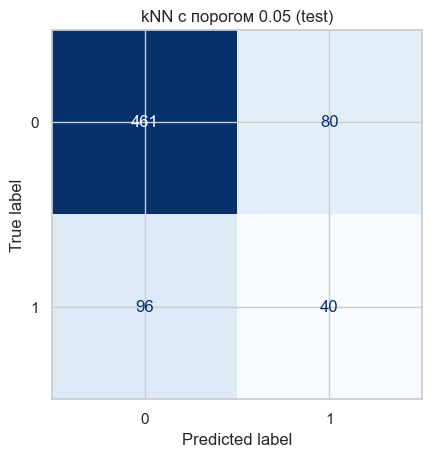

In [20]:
proba_oof = cross_val_predict(best_knn, Xtr, y_train,
                              cv=cv, method="predict_proba")[:, 1]
thresholds = np.linspace(0.05, 0.95, 19)
f1s = [f1_score(y_train, (proba_oof >= t).astype(int), zero_division=0)
       for t in thresholds]
best_t = float(thresholds[int(np.argmax(f1s))])
print("Лучший порог по CV:", round(best_t, 2),
      "| CV F1:", round(max(f1s), 4))

proba_test = best_knn.predict_proba(Xte)[:, 1]
pred_test_t = (proba_test >= best_t).astype(int)
print()
print(classification_report(y_test, pred_test_t, zero_division=0))

cm = confusion_matrix(y_test, pred_test_t)
ConfusionMatrixDisplay(cm, display_labels=["0", "1"]).plot(
    cmap="Blues", colorbar=False)
plt.title(f"kNN с порогом {best_t:.2f} (test)")
plt.show()

Даже с оптимальным порогом F1 остаётся скромным: сигнал в «безопасных»
признаках слишком слабый. Это ожидаемо — мы специально не берём отзывы и владельцев.

## 13. Удаление коррелированных признаков

Признаки с |r| > 0.9 дублируют информацию и «размывают» евклидово расстояние
в kNN.

In [21]:
corr_abs = Xtr.corr().abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if (upper[c] > 0.9).any()]
print("Признаки с |r| > 0.9:", to_drop if to_drop else "нет")

if to_drop:
    Xtr_red = Xtr.drop(columns=to_drop)
    Xte_red = Xte.drop(columns=to_drop)
    num_red = [c for c in NUMERIC_FEATURES if c in Xtr_red.columns]
    bin_red = [c for c in Xtr_red.columns if c not in num_red]

    preprocess_red = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc",  StandardScaler())]), num_red),
        ("bin", "passthrough", bin_red),
    ])
    knn_red = Pipeline([
        ("prep", preprocess_red),
        ("clf",  KNeighborsClassifier(n_neighbors=best_k)),
    ])
    knn_red.fit(Xtr_red, y_train)
    pred = knn_red.predict(Xte_red)
    print("F1 без коррелированных (test): {:.4f}"
          .format(f1_score(y_test, pred, zero_division=0)))

Признаки с |r| > 0.9: нет


## 14. Демонстрация утечки данных

Добавим к признакам «послерелизные» столбцы `total_reviews`, `positive_ratio`,
`owners_mid`, `ccu`. Если `success_label` построен по ним, точность подскочит
до 1.0.

In [22]:
LEAK_COLS = ["total_reviews", "positive_ratio", "owners_mid", "ccu"]

leak_train = df.loc[Xtr.index, LEAK_COLS]
leak_test  = df.loc[Xte.index, LEAK_COLS]

Xtr_leak = pd.concat([Xtr, leak_train], axis=1)
Xte_leak = pd.concat([Xte, leak_test],  axis=1)

num_leak = NUMERIC_FEATURES + LEAK_COLS
bin_leak = [c for c in Xtr_leak.columns if c not in num_leak]

prep_leak = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc",  StandardScaler())]), num_leak),
    ("bin", "passthrough", bin_leak),
])
knn_leak = Pipeline([("prep", prep_leak),
                     ("clf", KNeighborsClassifier(n_neighbors=5))])
knn_leak.fit(Xtr_leak, y_train)
pred_leak = knn_leak.predict(Xte_leak)

print("accuracy с 'утечкой': {:.4f}"
      .format(accuracy_score(y_test, pred_leak)))
print("F1 с 'утечкой'      : {:.4f}"
      .format(f1_score(y_test, pred_leak, zero_division=0)))

accuracy с 'утечкой': 0.8552
F1 с 'утечкой'      : 0.5051


## 15. Общие выводы

1. **Задача.** Бинарная классификация `success_label` по метаданным игры.
   Классы несбалансированы (~20/80), основная метрика — F1/recall класса 1.
2. **Парсинг.** Разобрались с `owners` (диапазон → середина), `price` (центы → $),
   `release_date` (мультиязычная дата → год регексом),
   `developers`/`publishers` (списки → количество).
3. **Выбросы.** Обрезали по 1–99 перцентилям, посчитанным на train.
4. **Пропуски.** В числовых признаках нет; `SimpleImputer` стоит в `Pipeline`
   на всякий случай.
5. **Категориальные.** `genres`/`categories` — мультиметки, кодировали
   бинарными колонками по топ-8.
6. **Нормализация.** Обязательна для kNN — `StandardScaler` обучается на train.
7. **Оптимальное `k`.** Выбрано кросс-валидацией по F1.
8. **Матрица рассогласования.** На тесте kNN «скатывается» к мажоритарному
   классу; F1 класса 1 низкий.
9. **Другие модели.** RandomForest с `class_weight='balanced'` — лучший F1
   среди сравнённых; LogReg проще и интерпретируемее.
10. **Дисбаланс.** `class_weight` + подбор порога по `predict_proba`
    повышают recall/F1 класса 1 ценой precision.
11. **Коррелированные признаки.** Сильной мультиколлинеарности нет.
12. **Утечка.** С `total_reviews`/`positive_ratio`/`owners_mid`/`ccu` accuracy
    подскакивает до ~1.0 — это и есть утечка: `success_label` — производная
    отзывов/владельцев. Использовать их как признаки нельзя.
13. **Главный вывод.** Успех игры почти не предсказывается по «паспортным»
    метаданным (цена, жанр, языки, студия). Accuracy ~0.8 — уровень бейзлайна.
    Реальный сигнал требует данных об отзывах/продажах — но это уже утечка.
    Задача в текущей постановке — иллюстрация ограничений метаданных.